1.1 第⼀个代码框：⾝份与环境记录

In [13]:
import os
import uuid
import hashlib
import platform
import numpy as np
from scipy import linalg, optimize, stats
import matplotlib.pyplot as plt
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20244080116
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] D:\conda\conda_envs\myenv1
[学号] 20244080116
[机器指纹] 5ec80ac0c8f60ff8
[RUN_ID] 20244080116-5ec80ac0c8f60ff8


⼆、实验内容与过程

实验1：NumPy 数组、数据类型与索引

1. 分别创建整数、浮点数和布尔值 ndarray，输出每个数组的 dtype、shape 和
ndim。解释 NumPy 数组的数据类型与 Python 列表的差别。

答：Python列表里可以同时存放不同类型的数据 如：`[1, 2.5, "abc"]`；没有固定类型，存储的是对象引用，运算慢。ndarray (Numpy 数组)是同一个数组内所有元素必须是相同数据类型；连续内存存储，计算速度更快；有固定`dtype`。

In [2]:
arrays = {
    "整数数组": np.array([1, 2, 3, 4]),
    "浮点数数组": np.array([1.1, 2.2, 3.3, 4.4]),
    "布尔数组": np.array([True, False, True, False]),
}

for name, arr in arrays.items():
    print(f"===={name}====")
    print("数组：", arr)
    print("dtype：", arr.dtype)
    print("shape：", arr.shape)
    print("ndim：", arr.ndim)

====整数数组====
数组： [1 2 3 4]
dtype： int64
shape： (4,)
ndim： 1
====浮点数数组====
数组： [1.1 2.2 3.3 4.4]
dtype： float64
shape： (4,)
ndim： 1
====布尔数组====
数组： [ True False  True False]
dtype： bool
shape： (4,)
ndim： 1


2. ⽤ np.arange(12) 创建⼀维数组，并分别变为形状 (3, 4) 和 (2, 3, 2) 的
数组。展⽰数组内容，说明改变形状时元素总数必须满⾜什么条件。

答：新shape所有维度数字相乘 = 原数组元素总个数，原数组 12 个元素：`3*4=12`；`2*3*2=12`。总数不匹配会报错。

In [3]:
arr1d = np.arange(12)
print("原始一维数组：\n", arr1d)

# 变形 (3,4)
arr_34 = arr1d.reshape(3, 4)
print("\nreshape(3,4):\n", arr_34)
print("shape:", arr_34.shape)

# 变形 (2,3,2)
arr_232 = arr1d.reshape(2, 3, 2)
print("\nreshape(2,3,2):\n", arr_232)
print("shape:", arr_232.shape)

原始一维数组：
 [ 0  1  2  3  4  5  6  7  8  9 10 11]

reshape(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
shape: (3, 4)

reshape(2,3,2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
shape: (2, 3, 2)


3. 对形状为 (3, 4) 的数组完成以下索引：取第 2 ⾏、取第 1 ⾄第 3 列、取⼤于 6
的元素，并分别输出结果及其形状。

In [4]:
print("原数组arr_34：\n", arr_34)

# 取第2行
row2 = arr_34[1, :]
print("\n取第2行：", row2)
print("shape：", row2.shape)

# 取第1~3列：列索引0,1,2  切片 0:3
col1to3 = arr_34[:, 0:3]
print("\n取第1至第3列：\n", col1to3)
print("shape：", col1to3.shape)

# 取大于6的元素
greater6 = arr_34[arr_34 > 6]
print("\n大于6的元素：", greater6)
print("shape：", greater6.shape)

原数组arr_34：
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

取第2行： [4 5 6 7]
shape： (4,)

取第1至第3列：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]
shape： (3, 3)

大于6的元素： [ 7  8  9 10 11]
shape： (5,)


4. 使⽤ np.arange(10) 分别选出“⼩于 2 或⼤于 7”和“⼤于 3 且⼩于 7”的元素。使
⽤括号配合 |、& 或 np.logical_or()、np.logical_and()。

In [5]:
arr = np.arange(10)
print("原始数组：", arr)

# 小于2 或 大于7
res_or = arr[(arr < 2) | (arr >7)]
res_or_lg = arr[np.logical_or(arr<2, arr>7)]
print("\n小于2或大于7：")
print("res_or:", res_or)
print("res_or_lg:", res_or_lg)

# 大于3 且 小于7
res_and = arr[(arr>3) & (arr<7)]
res_and_lg = arr[np.logical_and(arr>3, arr<7)]
print("\n大于3且小于7：")
print("res_and:", res_and)
print("res_and_lg:", res_and_lg)

原始数组： [0 1 2 3 4 5 6 7 8 9]

小于2或大于7：
res_or: [0 1 8 9]
res_or_lg: [0 1 8 9]

大于3且小于7：
res_and: [4 5 6]
res_and_lg: [4 5 6]


5. 构造两个形状为 (2, 2) 的数组，对⽐ *、np.multiply() 与 @、
np.matmul() 的结果，说明逐元素乘法与矩阵乘法的区别。

答：`*` 和 `np.multiply()`是逐元素乘法，对应位置元素两两相乘，两个数组 shape 必须完全一样。`@` 和 `np.matmul()`是数学矩阵乘法，遵循矩阵乘法规则：A 的列数必须等于 B 的行数。

In [6]:
A = np.array([[1,2],
              [3,4]])
B = np.array([[5,6],
              [7,8]])

print("数组A：\n",A)
print("数组B：\n",B)

# 逐元素乘法
elem_mul1 = A * B
elem_mul2 = np.multiply(A,B)
print("\n逐元素乘法 A*B：\n", elem_mul1)
print("np.multiply(A,B)：\n", elem_mul2)

# 矩阵乘法
mat_mul1 = A @ B
mat_mul2 = np.matmul(A,B)
print("\n矩阵乘法 A @ B：\n", mat_mul1)
print("np.matmul(A,B)：\n", mat_mul2)

数组A：
 [[1 2]
 [3 4]]
数组B：
 [[5 6]
 [7 8]]

逐元素乘法 A*B：
 [[ 5 12]
 [21 32]]
np.multiply(A,B)：
 [[ 5 12]
 [21 32]]

矩阵乘法 A @ B：
 [[19 22]
 [43 50]]
np.matmul(A,B)：
 [[19 22]
 [43 50]]


实验2：随机抽样、统计与缺失值

1. 使⽤ np.random ⽣成 1000 个均值为 70、标准差为 10 的模拟成绩；⽤np.clip
将数值限制在 0〜100 范围内。输出样本数、最⼩值、最⼤值、均值、标准差和极
差。

In [7]:
# 生成1000个均值70，标准差10 的正态分布成绩
np.random.seed(42)  # 设置随机种子，保证每次运行结果固定
scores = np.random.normal(70, 10, 1000)
# 裁剪到 [0,100]
scores = np.clip(scores, a_min=0, a_max=100)

n = len(scores)
min_val = np.min(scores)
max_val = np.max(scores)
mean_val = np.mean(scores)
std_val = np.std(scores)
range_val = max_val - min_val  # 极差

print(f"样本数：{n}")
print(f"最小值：{min_val:.2f}")
print(f"最大值：{max_val:.2f}")
print(f"均值：{mean_val:.2f}")
print(f"标准差：{std_val:.2f}")
print(f"极差：{range_val:.2f}")

样本数：1000
最小值：37.59
最大值：100.00
均值：70.18
标准差：9.76
极差：62.41


2. 从 np.arange(1, 11) 中不放回地抽取 5 个整数，⽐较均匀抽样与按整数⼤⼩成⽐例加权抽样的写法。

In [8]:
arr = np.arange(1,11)
print("原始数组：", arr)

# 均匀不放回抽样（每个元素概率相同）
sample_uniform = np.random.choice(arr, size=5, replace=False)
print("均匀不放回抽样结果：", sample_uniform)

# 按整数大小成比例加权不放回抽样
# 权重 = 元素本身大小，归一化作为采样概率
p = arr / np.sum(arr)
sample_weighted = np.random.choice(arr, size=5, replace=False, p=p)
print("按数值大小加权不放回抽样结果：", sample_weighted)

原始数组： [ 1  2  3  4  5  6  7  8  9 10]
均匀不放回抽样结果： [ 4  9  2  6 10]
按数值大小加权不放回抽样结果： [10  2  8  9  6]


3. 分别演⽰随机排列后保留原数组和原地打乱数组，打印操作前后的原数组以说明两种⽅式的区别。

区别：`np.random.permutation(arr)`：生成打乱后的新数组，原数组保持原样。`np.random.shuffle(arr)`：直接在原数组内存上修改，原数组被改变，无返回值

In [9]:
x = np.array([1,2,3,4,5,6])
print("原始数组 x：", x)

# np.random.permutation() → 返回新数组，**不改动原数组**
x_shuffle_new = np.random.permutation(x)
print("permutation 打乱后的新数组：", x_shuffle_new)
print("permutation后原数组x不变：", x)

# np.random.shuffle() → 原地打乱，直接修改原数组**
np.random.shuffle(x)
print("shuffle原地打乱后原数组x：", x)

原始数组 x： [1 2 3 4 5 6]
permutation 打乱后的新数组： [5 1 3 2 4 6]
permutation后原数组x不变： [1 2 3 4 5 6]
shuffle原地打乱后原数组x： [1 6 2 5 4 3]


4. 将模拟成绩的第 10、20、30 个值设为 np.nan。⽐较普通均值和忽略缺失值后的
均值，统计缺失值个数，并说明 nan 对普通统计函数的影响。

答：`np.nan`是缺失标记。常规统计函数`np.mean、np.sum`遇到 nan，结果直接为 nan；`np.nanmean / np.nansum`会自动跳过 nan 计算。

In [10]:
scores_nan = scores.copy()
# 第10、20、30个元素（下标9,19,29）设为nan
scores_nan[[9, 19, 29]] = np.nan

# 普通均值：只要包含nan，np.mean直接返回nan
mean_normal = np.mean(scores_nan)
# 忽略nan的均值
mean_ignorenan = np.nanmean(scores_nan)
# 统计缺失值数量
nan_count = np.sum(np.isnan(scores_nan))

print(f"普通np.mean（含nan）：{mean_normal}")
print(f"np.nanmean 忽略缺失值均值：{mean_ignorenan:.2f}")
print(f"缺失值个数：{nan_count}")

普通np.mean（含nan）：nan
np.nanmean 忽略缺失值均值：70.20
缺失值个数：3


5. 将含缺失值的模拟成绩及其序号整理成内存中的表格变量，供实验4直接使⽤；不要写⼊磁盘。

In [11]:
print("\n====内存表格====")
# 构造序号 0~999
idx = np.arange(len(scores_nan))
# 组合成结构化数组（内存表格，只在内存，不保存文件）
score_table = np.column_stack([idx, scores_nan])
print("表格形状：", score_table.shape)
print("前5行（序号，成绩）：\n", score_table[:5])
# 这个score_table变量可以直接给任务4复用


====内存表格====
表格形状： (1000, 2)
前5行（序号，成绩）：
 [[ 0.         74.96714153]
 [ 1.         68.61735699]
 [ 2.         76.47688538]
 [ 3.         85.23029856]
 [ 4.         67.65846625]]


实验3：SciPy 数值计算与 Matplotlib 可视化

1. 使⽤ scipy.linalg.solve() 解线性⽅程组 3x + y = 9 ，x + 2y = 8 ；⽤
NumPy 代⼊验证求得的解。

In [14]:
# 系数矩阵 A，右端向量 b
A = np.array([[3, 1],
              [1, 2]])
b = np.array([9, 8])
res = linalg.solve(A, b)
x_sol, y_sol = res[0], res[1]
print(f"方程组解：x = {x_sol:.4f}, y = {y_sol:.4f}")

# numpy代入验证
eq1 = 3 * x_sol + y_sol
eq2 = x_sol + 2 * y_sol
print(f"代入验证：3x+y = {eq1:.4f}, x+2y = {eq2:.4f}\n")

方程组解：x = 2.0000, y = 3.0000
代入验证：3x+y = 9.0000, x+2y = 8.0000



2. 使⽤ scipy.optimize.root() 求⽅程$x^2 - 2 = 0$的正根和负根，分别给出初始猜测值。打印求根是否成功以及结果，并检查函数值是否接近 0。

In [15]:
def f(x):
    return x**2 - 2

# 正根，初猜 2
root_pos = optimize.root(f, x0=2)
# 负根，初猜 -2
root_neg = optimize.root(f, x0=-2)

print("正根求解结果：")
print(f"是否成功：{root_pos.success}, 根 x = {root_pos.x[0]:.4f}, f(x)={f(root_pos.x[0]):.2e}")
print("负根求解结果：")
print(f"是否成功：{root_neg.success}, 根 x = {root_neg.x[0]:.4f}, f(x)={f(root_neg.x[0]):.2e}\n")

正根求解结果：
是否成功：True, 根 x = 1.4142, f(x)=8.88e-16
负根求解结果：
是否成功：True, 根 x = -1.4142, f(x)=8.88e-16



3. 使⽤ scipy.optimize.minimize() 求$f(x) = x^2 + x + 2$的最⼩值，报告极⼩点和函数值，并与解析结果⽐较。

In [16]:
def func_min(x):
    return x**2 + x + 2

# 初始猜测值
res_min = optimize.minimize(func_min, x0=0)
print(f"优化是否成功：{res_min.success}")
print(f"数值解极小点 x = {res_min.x[0]:.4f}")
print(f"数值解极小值 f(x) = {res_min.fun:.4f}")
# 解析解：二次函数 ax²+bx+c，顶点 x=-b/(2a) = -1/2 = -0.5
x_analytic = -1/(2*1)
f_analytic = x_analytic**2 + x_analytic + 2
print(f"解析解极小点 x = {x_analytic:.4f}, 解析极小值 f(x)={f_analytic:.4f}\n")

优化是否成功：True
数值解极小点 x = -0.5000
数值解极小值 f(x) = 1.7500
解析解极小点 x = -0.5000, 解析极小值 f(x)=1.7500



4. ⽣成两组独⽴的模拟样本：各 100 个观测值，第⼀组来⾃均值 0、标准差 1 的正态分布，第⼆组来⾃均值 1、标准差 1 的正态分布。固定随机种⼦，使⽤scipy.stats.ttest_ind() 进⾏独⽴样本 t 检验；报告 t 统计量、p 值及在0.05 显著性⽔平下的判断。

In [17]:
np.random.seed(42)  # 固定随机种子
sample1 = np.random.normal(loc=0, scale=1, size=100)
sample2 = np.random.normal(loc=1, scale=1, size=100)

t_stat, p_val = stats.ttest_ind(sample1, sample2)
print(f"t统计量：{t_stat:.4f}")
print(f"p值：{p_val:.4f}")
alpha = 0.05
if p_val < alpha:
    print(f"p < 0.05，拒绝原假设，两组均值存在显著差异")
else:
    print(f"p ≥ 0.05，不能拒绝原假设，两组均值无显著差异\n")

t统计量：-8.5515
p值：0.0000
p < 0.05，拒绝原假设，两组均值存在显著差异


5. ⽤ Matplotlib 为实验2的有效成绩画直⽅图，并另画箱线图；为函数 $y = x$、$y = x^2$、$y = x^3$ 在$0 \le x \le 5$上画同⼀坐标系的折线图。每张图包含标题、坐标轴标签，折线图包含图例。直接在 Notebook 中显⽰图像，不保存为⽂件。

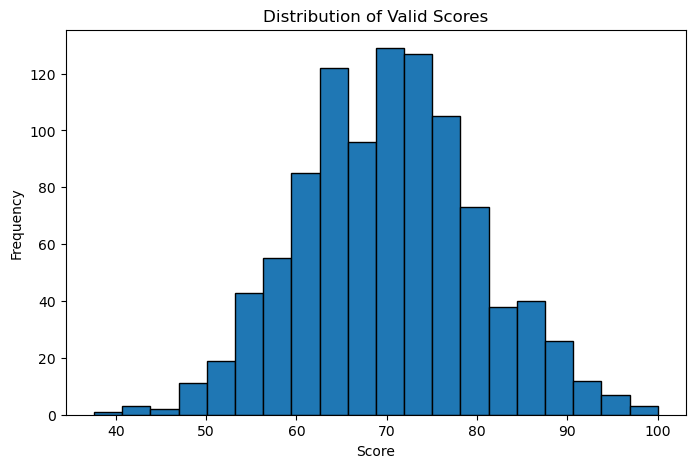

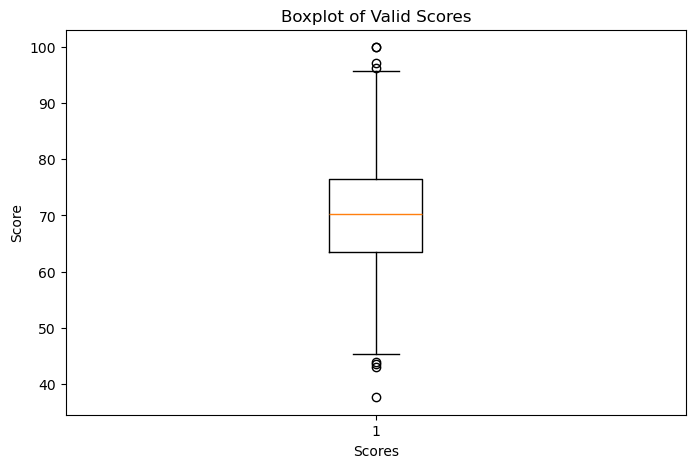

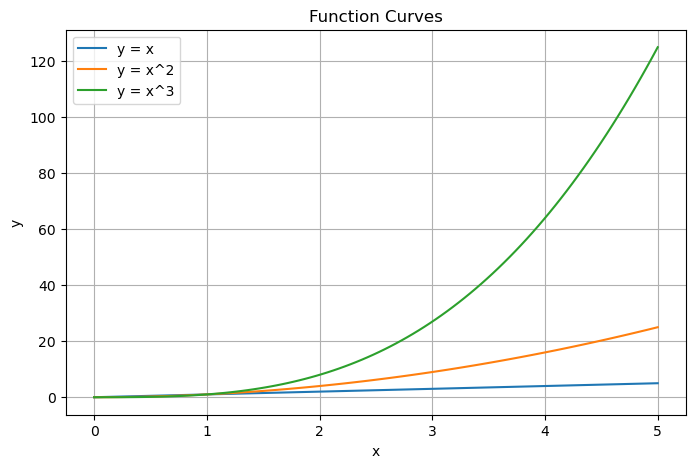

In [19]:
# 只保留非缺失成绩，用于绘图
valid_scores = scores_nan[~np.isnan(scores_nan)]

# 有效成绩直方图
plt.figure(figsize=(8, 5))
plt.hist(valid_scores, bins=20, edgecolor="black")
plt.title("Distribution of Valid Scores")
plt.xlabel("Score")
plt.ylabel("Frequency")
plt.show()

# 有效成绩箱线图
plt.figure(figsize=(8, 5))
plt.boxplot(valid_scores)
plt.title("Boxplot of Valid Scores")
plt.xlabel("Scores")
plt.ylabel("Score")
plt.show()

# y=x、y=x^2、y=x^3 的折线图
x_values = np.linspace(0, 5, 100)
plt.figure(figsize=(8, 5))
plt.plot(x_values, x_values, label="y = x")
plt.plot(x_values, x_values**2, label="y = x^2")
plt.plot(x_values, x_values**3, label="y = x^3")
plt.title("Function Curves")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

实验4：pandas Series、DataFrame 与内存中的CSV 读写

1. 使⽤以下模拟数据创建 DataFrame，⾏索引为姓名；计算 Total（三科总分）和
Average（三科平均分）两列。输出⾏索引、列名、前 3 ⾏和基本统计信息。

records = {
 "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],

 "Group": ["A", "A", "B", "B", "A", "B"],

 "Math": [88, 72, 91, 65, 79, 84],

 "English": [90, 68, 85, 73, 92, 77],
 
 "Python": [95, 80, 89, 70, 86, 82],

}

In [21]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records)
df = df.set_index("Name")   # 将Name设置为行索引

# 计算总分、平均分
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3

print("行索引：", df.index.tolist())
print("列名：", df.columns.tolist())
print("\n前3行数据：")
print(df.head(3))
print("\n基本统计信息 describe()：")
print(df.describe())
print("\n")

行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行数据：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息 describe()：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000




2. 分别⽤ loc 和 iloc 读取 Carol 的记录，并筛选平均分不低于 80 的学⽣。

In [23]:
# loc：按标签索引（行名字Carol）
carol_loc = df.loc["Carol"]
print("loc['Carol']：")
print(carol_loc)

# iloc：按位置索引，Carol是第2行（从0开始）
carol_iloc = df.iloc[2]
print("\niloc[2]：")
print(carol_iloc)

# 筛选平均分不低于80
high_avg = df[df["Average"] >= 80]
print("\n平均分≥80的学生：")
print(high_avg)
print("\n")

loc['Carol']：
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc[2]：
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分≥80的学生：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000




3. 分别⽤ mean(axis=0) 和 mean(axis=1) 计算三科成绩的列均值和每名学⽣的
⾏均值。

In [24]:
# axis=0：按列，每科的平均分
col_mean = df[["Math","English","Python"]].mean(axis=0)
print("三科列均值(axis=0)：")
print(col_mean)
# axis=1：按行，每个学生的平均分（和Average列一致）
row_mean = df[["Math","English","Python"]].mean(axis=1)
print("\n每个学生行均值(axis=1)：")
print(row_mean)
print("\n")

三科列均值(axis=0)：
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每个学生行均值(axis=1)：
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64




4. 使⽤ apply() 计算每名学⽣的三科最⾼分，使⽤ agg() ⼀次得到每科的最⼩值、
均值和最⼤值。任选⼀列使⽤ rank() 给学⽣排名

In [25]:
# apply 每行求三科最高分
df["MaxScore"] = df[["Math","English","Python"]].apply(lambda row: row.max(), axis=1)
print("增加MaxScore（单科最高分）：")
print(df)

# agg 一次得到每科 min mean max
agg_result = df[["Math","English","Python"]].agg(["min","mean","max"])
print("\nagg 每科最小、均值、最大值：")
print(agg_result)

# rank：用Python成绩排名，method="min"
df["Python_Rank"] = df["Python"].rank(ascending=False, method="min")
print("\n增加Python成绩排名(越高名次越靠前)：")
print(df[["Python","Python_Rank"]])
print("\n")

增加MaxScore（单科最高分）：
      Group  Math  English  Python  Total    Average  MaxScore
Name                                                          
Alice     A    88       90      95    273  91.000000        95
Bob       A    72       68      80    220  73.333333        80
Carol     B    91       85      89    265  88.333333        91
David     B    65       73      70    208  69.333333        73
Eva       A    79       92      86    257  85.666667        92
Frank     B    84       77      82    243  81.000000        84

agg 每科最小、均值、最大值：
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

增加Python成绩排名(越高名次越靠前)：
       Python  Python_Rank
Name                      
Alice      95          1.0
Bob        80          5.0
Carol      89          2.0
David      70          6.0
Eva        86          3.0
Frank      82          4.0




5. 按 Group 分组，统计每组⼈数和三科平均分。再⽤ transform('mean') 为每⾏
增加其所在组的 Python 平均分。

In [26]:
group_info = df.groupby("Group").agg(
    人数=("Math", "count"),
    Math均值=("Math","mean"),
    English均值=("English","mean"),
    Python均值=("Python","mean")
)
print("分组统计：每组人数、三科平均分")
print(group_info)

# transform：给每一行新增本组Python平均分
df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n增加本组Python平均分：")
print(df[["Group","Python","Group_Python_Mean"]])
print("\n")

分组统计：每组人数、三科平均分
       人数     Math均值  English均值   Python均值
Group                                     
A       3  79.666667  83.333333  87.000000
B       3  80.000000  78.333333  80.333333

增加本组Python平均分：
      Group  Python  Group_Python_Mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333




6. ⽤ filter() 保留 Python 平均分不低于 80 的组；输出保留的组和学⽣。

In [27]:
def group_filter_func(g):
    return g["Python"].mean() >= 80

df_filtered = df.groupby("Group").filter(group_filter_func)
print("filter保留Python组平均分≥80的组：")
print(df_filtered)
print("\n")

filter保留Python组平均分≥80的组：
      Group  Math  English  Python  Total    Average  MaxScore  Python_Rank  \
Name                                                                          
Alice     A    88       90      95    273  91.000000        95          1.0   
Bob       A    72       68      80    220  73.333333        80          5.0   
Carol     B    91       85      89    265  88.333333        91          2.0   
David     B    65       73      70    208  69.333333        73          6.0   
Eva       A    79       92      86    257  85.666667        92          3.0   
Frank     B    84       77      82    243  81.000000        84          4.0   

       Group_Python_Mean  
Name                      
Alice          87.000000  
Bob            87.000000  
Carol          80.333333  
David          80.333333  
Eva            87.000000  
Frank          80.333333  




7. 计算三科成绩之间的协⽅差矩阵和⽪尔森相关系数矩阵；选择其中⼀对科⽬，解释
协⽅差符号与相关系数⼤⼩的含义。

协方差符号代表两个变量变化方向；正数说明两门成绩倾向同增同减，负数代表此消彼长。协方差数值大小受成绩本身量纲影响，不能直接判断强弱。

皮尔逊相关系数 r：范围 \([-1,1]\)。\(r>0\) 正相关，\(r<0\) 负相关；\(|r|\) 越靠近 1，线性相关性越强；接近 0 代表几乎无线性相关。它消除了量纲影响，可以直接比较相关强弱。

In [28]:
score_cols = ["Math","English","Python"]
cov_matrix = df[score_cols].cov()
corr_matrix = df[score_cols].corr()
print("协方差矩阵 cov：")
print(cov_matrix)
print("\n皮尔逊相关系数矩阵 corr：")
print(corr_matrix)

协方差矩阵 cov：
              Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

皮尔逊相关系数矩阵 corr：
             Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000
